# Distilling the Knowledge in a Neural Network: MNIST reproduction

This notebook reproduces the MNIST experiment (Section 3) of Hinton, Vinyals & Dean, [*Distilling the Knowledge in a Neural Network*](https://arxiv.org/abs/1503.02531) (2015):

| Model | Paper test errors (of 10,000) |
|---|---|
| Teacher: 784-1200-1200-10, dropout + weight constraints + jitter | 67 |
| Student: 784-800-800-10, no regularization, true labels | 146 |
| Student: 784-800-800-10, no regularization, distilled from the teacher at T = 20 | 74 |

Running every cell from top to bottom trains the teacher, then both students, then shows a results table and the training curves.

**How to open it.** From the repository root:

```bash
uv sync
uv run --with jupyter jupyter lab mnist/reproduce.ipynb
```


The training code lives in `common.py`, `train_teacher.py` and `train_student.py` next to this notebook; the notebook only calls it, so it trains exactly what the command-line scripts train.

## Setup

In [5]:
import json
import sys
import time
from pathlib import Path

# Works whether Jupyter was started in the repository root or in mnist/.
HERE = next(p for p in (Path.cwd(), Path.cwd() / "mnist") if (p / "common.py").exists())
sys.path.insert(0, str(HERE))

import matplotlib.pyplot as plt
import torch
from IPython.display import Markdown, display

import train_student
import train_teacher
from common import lr_at, momentum_at

print("torch", torch.__version__, "| CUDA available:", torch.cuda.is_available())

torch 2.14.1+cu130 | CUDA available: True


In [6]:
QUICK = False        # True: QUICK_EPOCHS per run, only to check that the pipeline works
QUICK_EPOCHS = 50
REUSE = True         # skip a run whose saved results match its settings (re-run the plots without retraining)
DEVICE = 'cuda'       # None: CUDA if available, else CPU

# Checkpoints and results go to mnist/checkpoints/<PREFIX><run>.pt and .json,
# so the notebook never overwrites the command-line runs.
PREFIX = "nb_quick_" if QUICK else "nb_"

## Settings

The paper gives the architectures, the regularizers, the temperature and the results, but no training hyperparameters. For those it points to its reference [5], Hinton et al. (2012), [*Improving neural networks by preventing co-adaptation of feature detectors*](https://arxiv.org/abs/1207.0580), Appendix A. The settings below follow [5] except where noted.

The training dataset is MNIST, which contains 60,000 traning images and 10,000 test images of handwritten digits.
Optimizer: SGD with momentum.
| Setting | Value |
|---|---|
| Update rule | $Δw = p Δw − (1 − p) ε ∇L$, then max-norm projection |
| Learning rate | $ε = lr · 0.998^{epoch}$ |
| Momentum p | 0.5 → 0.99 linearly over the first 500 epochs |
| Epochs, batch, init | 3000, 100, weights $N(0, 0.01²)$, biases 0 |
| Teacher dropout | 0.2 on the input, 0.5 on the hidden units |
| Teacher max-norm | L2 norm of each hidden unit's incoming weights ≤ 2 |
| Teacher jitter | shifts of up to 2 pixels in each direction |
| Students | no dropout, no max-norm, no jitter |
| Student lr | 0.1 for both students |
| Distillation loss | $\mathcal{L}_{\text{total}}=(1-w)T^2\underbrace{\mathrm{CE}\left(P_{\text{teacher}}^{(T)},P_{\text{student}}^{(T)}\right)}_{\text{Soft-label loss}}+w\underbrace{\mathrm{CE}\left(y_{\text{true}},P_{\text{student}}^{(1)}\right)}_{\text{Hard-label loss}}$ |
| Temperature T | 20 |
| Hard-label weight w | 0.1 |

Change any value here before running the training cells. Set `wandb=True` to also log to Weights & Biases (needs `uv run wandb login` first).

In [7]:
OPTIM = dict(
    optimizer="momentum", epochs=3000, batch_size=100, lr_decay=0.998,
    momentum_initial=0.5, momentum_final=0.99, momentum_epochs=500,
    init_std=0.01, seed=0, eval_every=25, wandb=False,
)
TEACHER = dict(OPTIM, hidden=1200, bias=True, p_in=0.2, p_hidden=0.5, max_norm=2.0, jitter=2, lr=1.0)
STUDENT = dict(OPTIM, hidden=800, bias=True, p_in=0.0, p_hidden=0.0, max_norm=0, jitter=0, lr=0.1, epochs=1000, wandb=True,)
STUDENT_HARD = dict(STUDENT, teacher="", temperature=1.0, hard_weight=1.0,)
STUDENT_DISTILL = dict(STUDENT, teacher=f"checkpoints/{PREFIX}teacher.pt", temperature=20.0, hard_weight=0.1, epochs=1000)

if QUICK:
    for settings in (TEACHER, STUDENT_HARD, STUDENT_DISTILL):
        settings.update(epochs=QUICK_EPOCHS, eval_every=5)

In [8]:
def run(make_args, train_fn, settings, name):
    # Train one model, or reuse its saved results when REUSE is on and the settings match.
    args = make_args(settings, PREFIX + name, device=DEVICE)
    results = args.out.with_suffix(".json")
    if REUSE and results.exists():
        saved = json.loads(results.read_text())
        if all(saved["config"].get(k) == v for k, v in settings.items()):
            print(f"{name}: reusing {results}")
            return saved["history"]
    start = time.time()
    history = train_fn(args)
    print(f"{name}: {(time.time() - start) / 60:.1f} min")
    return history


histories = {}

## 1. Teacher

In [9]:
histories["teacher"] = run(train_teacher.make_args, train_teacher.run_teacher, TEACHER, "teacher")

teacher: reusing /nvme1/users/shuwenxue/distillation/mnist/checkpoints/nb_teacher.json


## 2. Students

Both students have the same architecture, initialization and optimizer; only the targets differ. The distilled student reads the teacher trained above and prints its test errors first.

In [10]:
histories["student_hard"] = run(train_student.make_args, train_student.run_student, STUDENT_HARD, "student_hard")

student_hard: reusing /nvme1/users/shuwenxue/distillation/mnist/checkpoints/nb_student_hard.json


In [11]:
histories["student_distill"] = run(train_student.make_args, train_student.run_student, STUDENT_DISTILL, "student_distill")

student_distill: reusing /nvme1/users/shuwenxue/distillation/mnist/checkpoints/nb_student_distill.json


In [12]:
import torch.nn.functional as F
from common import load_model, load_mnist, logits_of
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
teacher = load_model('./checkpoints/nb_teacher.pt', dev)
x_train, y_train, x_test, y_test = load_mnist(dev)
for name, x in (('train', x_train), ('test', x_test)):
    z = logits_of(teacher, x)
    for T in (1, 2, 5, 10, 20, 200, 2000):
        log_p = F.log_softmax(z / T, dim=1)
        H = -(log_p.exp() * log_p).sum(dim=1)
        print(f'{name:5s} T={T:2d}  mean H = {H.mean():.4f}  (min {H.min():.4f}, max {H.max():.4f})')
print()
print('max possible ln10 = 2.3026 when the output is uniform')


train T= 1  mean H = 0.0059  (min 0.0000, max 1.1845)
train T= 2  mean H = 0.0551  (min 0.0000, max 1.7062)
train T= 5  mean H = 0.7112  (min 0.0047, max 2.1689)
train T=10  mean H = 1.6964  (min 0.3273, max 2.2719)
train T=20  mean H = 2.1590  (min 1.4899, max 2.2954)
train T=200  mean H = 2.3015  (min 2.2961, max 2.3025)
train T=2000  mean H = 2.3026  (min 2.3025, max 2.3026)
test  T= 1  mean H = 0.0138  (min 0.0000, max 1.5533)
test  T= 2  mean H = 0.0682  (min 0.0000, max 1.9281)
test  T= 5  mean H = 0.7192  (min 0.0216, max 2.2088)
test  T=10  mean H = 1.6970  (min 0.4942, max 2.2801)
test  T=20  mean H = 2.1583  (min 1.6276, max 2.2974)
test  T=200  mean H = 2.3014  (min 2.2970, max 2.3025)
test  T=2000  mean H = 2.3026  (min 2.3025, max 2.3026)

max possible ln10 = 2.3026 when the output is uniform


### Loss Function Analysis

The knowledge distillation loss is defined as: $L=\alpha T^2L_{\text{soft}}+(1-\alpha)L_{\text{hard}}$

The soft cross-entropy can be decomposed into: $L_{\text{soft}}=H(p_T)+D_{\mathrm{KL}}(p_T\parallel q_T)$

Since $D_{\mathrm{KL}}\geq0$, the theoretical lower bound of the soft loss is the **Teacher's entropy $H(p_T)$**, achieved when the Student perfectly matches the Teacher.

At **$T=20$**, the Teacher entropy is 2.1583.

For the combined loss, the theoretical lower bound is: $\boxed{L\geq\alpha T^2H(p_T)}$

For example, if $T^2L_{\text{soft,min}}=400\times2.1583\times0.9\approx777$

This explains why the training loss may remain numerically large even after convergence. The observed loss of approximately 777.25 is consistent with this bound if the implementation uses $\alpha=0.9$ and mean reduction on the same data distribution.

**Key takeaway:** A large soft cross-entropy does not necessarily indicate poor distillation. The more informative metric is $D_{\mathrm{KL}}(p_T\parallel q_T)$, which approaches zero as the Student matches the Teacher's probability distribution.

## 3. Results

In [13]:
PAPER = {"teacher": 67, "student_hard": 146, "student_distill": 74}

rows = ["| Model | Test errors | Paper | Train errors |", "|---|---|---|---|"]
for name, history in histories.items():
    last = history[-1]
    rows.append(f"| {name} | {last['test_errors']} | {PAPER[name]} | {last.get('train_errors', '')} |")
if {"student_hard", "student_distill"} <= histories.keys():
    ours = histories["student_distill"][-1]["test_errors"] / histories["student_hard"][-1]["test_errors"]
    rows.append(f"\nDistilled / true-label student errors: **{ours:.2f}** (paper: {74 / 146:.2f})")
display(Markdown("\n".join(rows)))

| Model | Test errors | Paper | Train errors |
|---|---|---|---|
| teacher | 66 | 67 | 23 |
| student_hard | 177 | 146 | 0 |
| student_distill | 83 | 74 | 14 |

Distilled / true-label student errors: **0.47** (paper: 0.51)

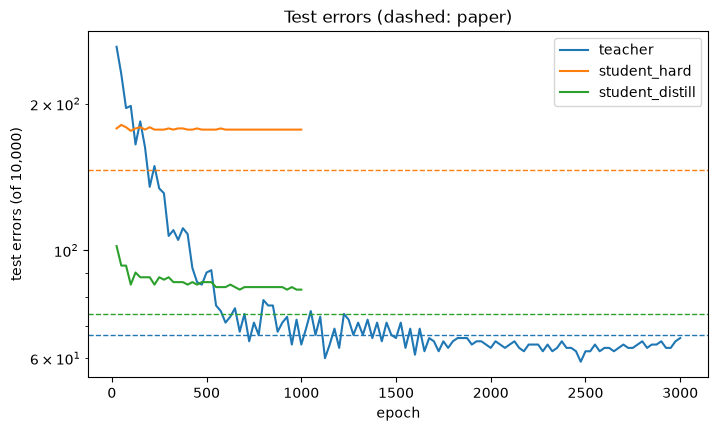

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for (name, history), color in zip(histories.items(), ("C0", "C1", "C2")):
    ax.plot([h["epoch"] for h in history], [h["test_errors"] for h in history], color=color, label=name)
    ax.axhline(PAPER[name], color=color, linestyle="--", linewidth=1)
ax.set(xlabel="epoch", ylabel="test errors (of 10,000)", yscale="log", title="Test errors (dashed: paper)")
ax.legend()
plt.show()

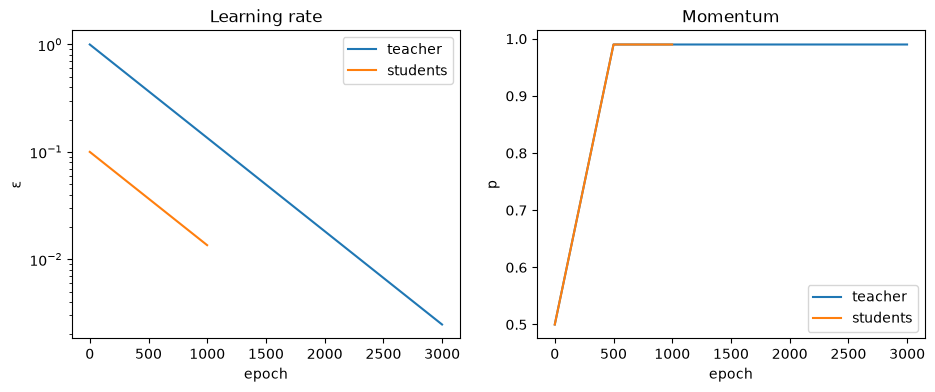

In [15]:
# Learning rate and momentum schedules (the same rule for every run, with different lr).
fig, (ax_lr, ax_mom) = plt.subplots(1, 2, figsize=(11, 4))
for name, make_args, settings in (
    ("teacher", train_teacher.make_args, TEACHER),
    ("students", train_student.make_args, STUDENT_HARD),
):
    args = make_args(settings, "schedule")
    epochs = range(args.epochs)
    ax_lr.plot(epochs, [lr_at(args, e) for e in epochs], label=name)
    if args.optimizer == "momentum":
        ax_mom.plot(epochs, [momentum_at(args, e) for e in epochs], label=name)
ax_lr.set(xlabel="epoch", ylabel="ε", yscale="log", title="Learning rate")
ax_mom.set(xlabel="epoch", ylabel="p", title="Momentum")
ax_lr.legend()
ax_mom.legend()
plt.show()

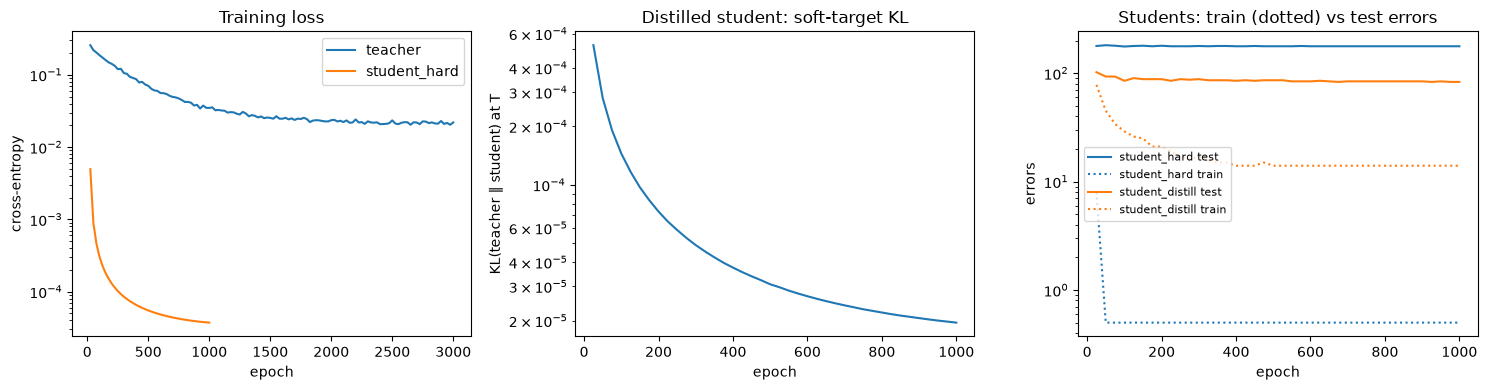

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for name in ("teacher", "student_hard"):
    if name in histories:
        h = histories[name]
        axes[0].plot([e["epoch"] for e in h], [e["train_loss"] for e in h], label=name)
axes[0].set(xlabel="epoch", ylabel="cross-entropy", yscale="log", title="Training loss")
axes[0].legend()

if "student_distill" in histories:
    h = histories["student_distill"]
    axes[1].plot([e["epoch"] for e in h], [e["train_soft_kl"] for e in h])
axes[1].set(xlabel="epoch", ylabel="KL(teacher ‖ student) at T", yscale="log", title="Distilled student: soft-target KL")

for name in ("student_hard", "student_distill"):
    if name in histories:
        h = histories[name]
        line, = axes[2].plot([e["epoch"] for e in h], [e["test_errors"] for e in h], label=f"{name} test")
        axes[2].plot([e["epoch"] for e in h], [max(e["train_errors"], 0.5) for e in h], color=line.get_color(), linestyle=":", label=f"{name} train")
axes[2].set(xlabel="epoch", ylabel="errors", yscale="log", title="Students: train (dotted) vs test errors")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Notes

- **Reading the losses.** The training loss of the teacher is measured with dropout and jitter on, so it stays above 0. The true-label student reaches a training loss of about 0, with 0 training errors: it memorizes the training set, and its test errors stop changing. The distilled student's loss contains the entropy of the teacher's soft targets, which the student cannot reduce (about 0.9 · 400 · 2.16 ≈ 777 at T = 20), so the plot shows only the KL part, whose minimum is 0.
- **Our results with these settings** (one run each, on a GPU): teacher 66 test errors, true-label student 177, distilled student about 85. Distillation roughly halves the student's errors, as in the paper (74 / 146 = 0.51). The absolute numbers differ from the paper's because the student's training settings are not given there.
- **Run-to-run noise.** Repeating a run with another `seed` changes the test errors by a few; compare differences larger than that.
- **No validation set.** Every model is trained on all 60,000 training images and evaluated on the 10,000 test images, as in the paper. The settings marked "chosen here" were picked by looking at test errors, so they are not a tuned, held-out result.

## 4. Omitting the digit 3

The same distillation, but with every 3 removed from the transfer set, so the student never sees a 3. Paper: 206 test errors, 133 of them on the 1010 test 3s; raising the bias of the 3 class by 3.5 (chosen on the test set) gives 109 errors, 14 on 3s.

In [17]:
STUDENT_NO3 = dict(STUDENT_DISTILL, exclude_digits=[3])
no3_history = run(train_student.make_args, train_student.run_student, STUDENT_NO3, "student_distill_no3")
last = no3_history[-1]
print(f"test errors {last['test_errors']} ({last['test_errors_excluded']} on 3s); paper: 206 (133 on 3s)")

student_distill_no3: reusing /nvme1/users/shuwenxue/distillation/mnist/checkpoints/nb_student_distill_no3.json
test errors 193 (119 on 3s); paper: 206 (133 on 3s)


In [18]:
from common import load_mnist, load_model, logits_of
from shift_bias import shift_errors

no3_args = train_student.make_args(STUDENT_NO3, PREFIX + "student_distill_no3", device=DEVICE)
no3_model = load_model(no3_args.out, no3_args.device)
_, _, x_test, y_test = load_mnist(no3_args.device)
shifts = [i * 0.5 for i in range(21)]
rows = shift_errors(logits_of(no3_model, x_test), y_test, 3, shifts)
best = min(rows, key=lambda r: r[1])

table = ["| Added to the bias of 3 | Test errors | On 3s (of 1010) |", "|---|---|---|"]
table += [f"| {s:.1f} | {e} | {e3} |" + (" **fewest**" if (s, e, e3) == best else "") for s, e, e3 in rows]
display(Markdown("\n".join(table)))

| Added to the bias of 3 | Test errors | On 3s (of 1010) |
|---|---|---|
| 0.0 | 193 | 119 |
| 0.5 | 168 | 93 |
| 1.0 | 151 | 74 |
| 1.5 | 141 | 62 |
| 2.0 | 127 | 44 |
| 2.5 | 120 | 35 | **fewest**
| 3.0 | 120 | 27 |
| 3.5 | 125 | 24 |
| 4.0 | 121 | 14 |
| 4.5 | 135 | 10 |
| 5.0 | 147 | 5 |
| 5.5 | 160 | 3 |
| 6.0 | 176 | 3 |
| 6.5 | 192 | 1 |
| 7.0 | 211 | 0 |
| 7.5 | 240 | 0 |
| 8.0 | 273 | 0 |
| 8.5 | 311 | 0 |
| 9.0 | 357 | 0 |
| 9.5 | 406 | 0 |
| 10.0 | 481 | 0 |

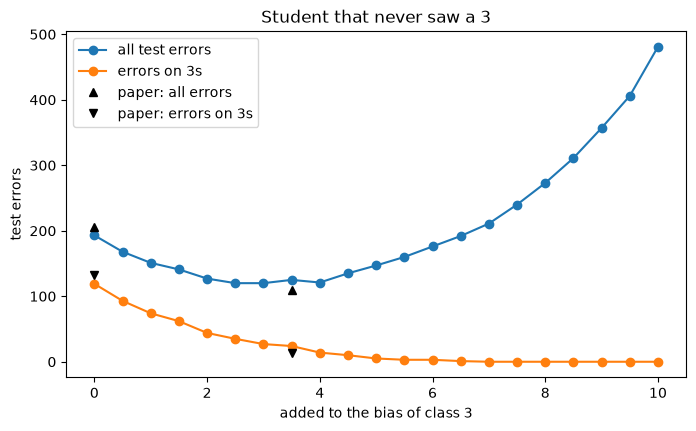

In [19]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(shifts, [r[1] for r in rows], marker="o", label="all test errors")
ax.plot(shifts, [r[2] for r in rows], marker="o", label="errors on 3s")
ax.plot([0, 3.5], [206, 109], "k^", label="paper: all errors")
ax.plot([0, 3.5], [133, 14], "kv", label="paper: errors on 3s")
ax.set(xlabel="added to the bias of class 3", ylabel="test errors", title="Student that never saw a 3")
ax.legend()
plt.show()

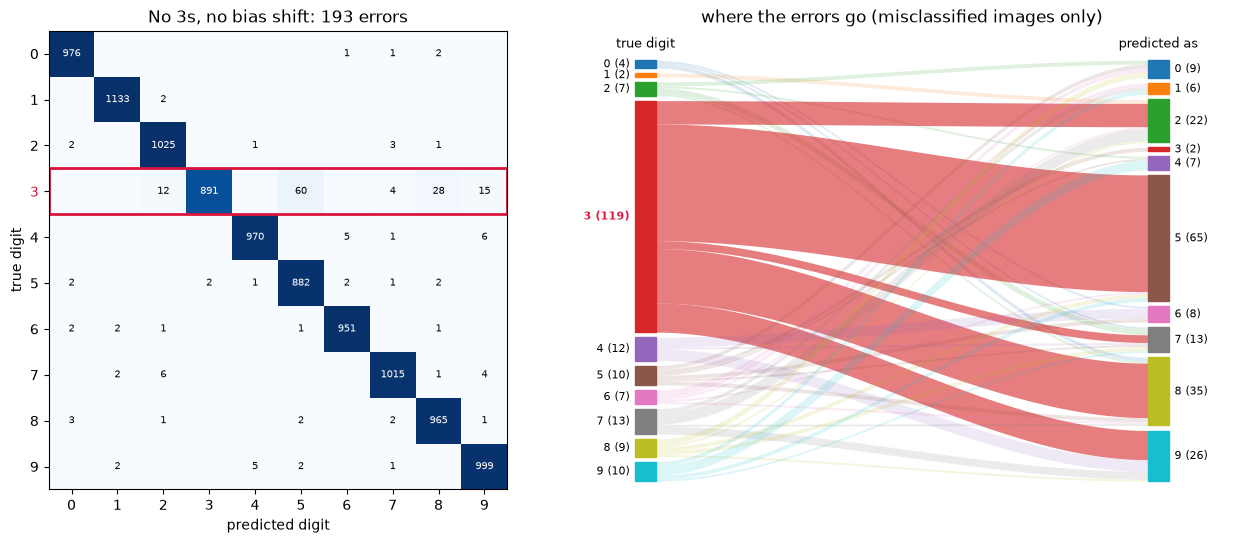

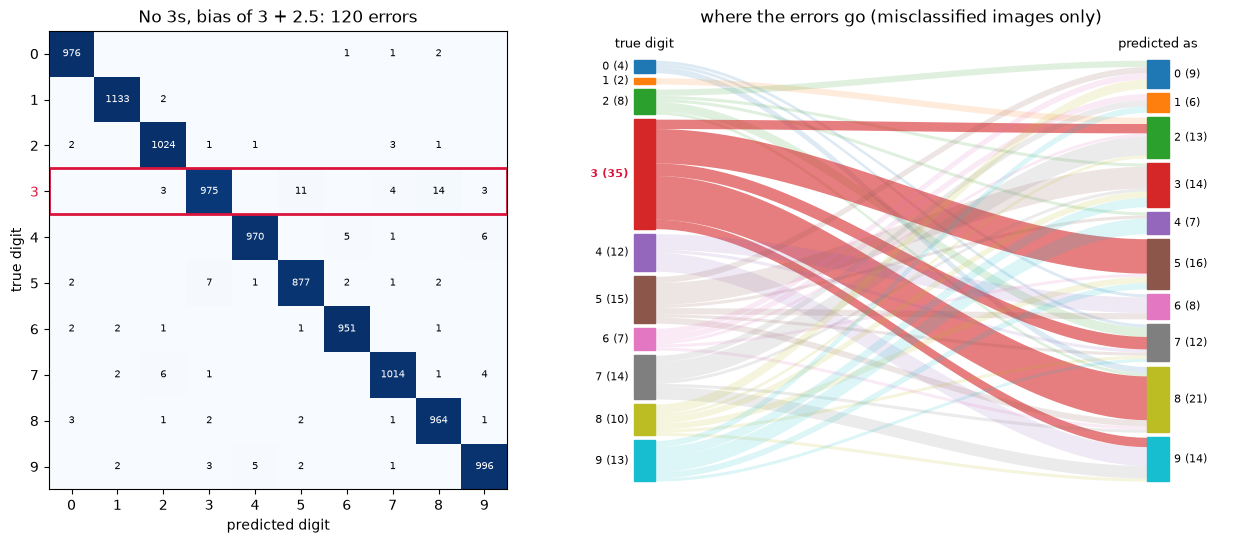

In [20]:
from plots import predictions, show_predictions

show_predictions(y_test, predictions(no3_model, x_test), highlight=[3], title="No 3s, no bias shift")
show_predictions(y_test, predictions(no3_model, x_test, [3], best[0]), highlight=[3], title=f"No 3s, bias of 3 + {best[0]}")

## 5. Only 7s and 8s in the transfer set

The student sees only 7s and 8s during distillation. Paper: 47.3% test errors; reducing the biases of 7 and 8 by 7.6 gives 13.2%. Raising the biases of the eight unseen digits by s gives the same predictions as reducing those of 7 and 8 by s.

In [21]:
STUDENT_ONLY78 = dict(STUDENT_DISTILL, exclude_digits=[0, 1, 2, 3, 4, 5, 6, 9])
only78_history = run(train_student.make_args, train_student.run_student, STUDENT_ONLY78, "student_distill_only78")
last = only78_history[-1]
print(f"test errors {last['test_errors']} ({last['test_errors'] / 100:.1f}%), "
      f"{last['test_errors_excluded']} on the unseen digits; paper: 47.3%")

student_distill_only78: reusing /nvme1/users/shuwenxue/distillation/mnist/checkpoints/nb_student_distill_only78.json
test errors 3477 (34.8%), 3473 on the unseen digits; paper: 47.3%


In [22]:
from common import load_mnist, load_model, logits_of
from shift_bias import shift_errors

only78_args = train_student.make_args(STUDENT_ONLY78, PREFIX + "student_distill_only78", device=DEVICE)
only78_model = load_model(only78_args.out, only78_args.device)
_, _, x_test, y_test = load_mnist(only78_args.device)
shifts = [i * 0.5 for i in range(21)]
rows78 = shift_errors(logits_of(only78_model, x_test), y_test, STUDENT_ONLY78["exclude_digits"], shifts)
best78 = min(rows78, key=lambda r: r[1])

table = ["| Added to the unseen digits' biases | Test error rate | Errors on unseen digits |", "|---|---|---|"]
table += [f"| {s:.1f} | {e / 100:.1f}% | {eu} |" + (" **fewest**" if (s, e, eu) == best78 else "") for s, e, eu in rows78]
display(Markdown("\n".join(table)))

| Added to the unseen digits' biases | Test error rate | Errors on unseen digits |
|---|---|---|
| 0.0 | 34.8% | 3473 |
| 0.5 | 32.0% | 3196 |
| 1.0 | 29.4% | 2934 |
| 1.5 | 27.1% | 2705 |
| 2.0 | 25.0% | 2492 |
| 2.5 | 23.0% | 2278 |
| 3.0 | 21.3% | 2108 |
| 3.5 | 20.1% | 1973 |
| 4.0 | 18.9% | 1840 |
| 4.5 | 17.8% | 1718 |
| 5.0 | 17.0% | 1617 |
| 5.5 | 16.2% | 1515 |
| 6.0 | 15.5% | 1415 |
| 6.5 | 14.8% | 1309 |
| 7.0 | 14.4% | 1240 |
| 7.5 | 14.2% | 1177 |
| 8.0 | 14.1% | 1112 | **fewest**
| 8.5 | 14.3% | 1079 |
| 9.0 | 14.6% | 1030 |
| 9.5 | 14.8% | 993 |
| 10.0 | 15.4% | 969 |

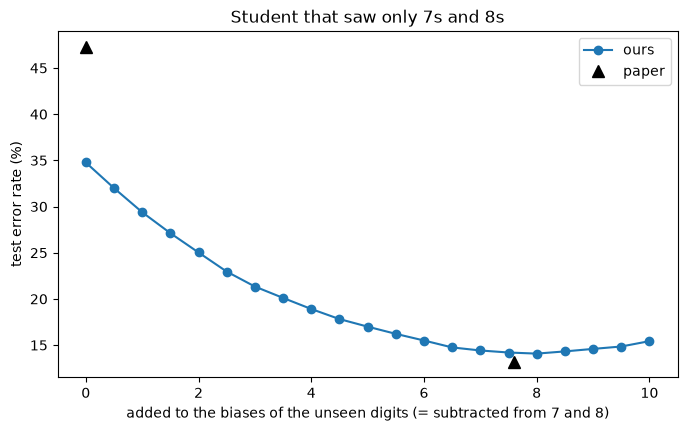

In [23]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(shifts, [r[1] / 100 for r in rows78], marker="o", label="ours")
ax.plot([0, 7.6], [47.3, 13.2], "k^", markersize=9, label="paper")
ax.set(xlabel="added to the biases of the unseen digits (= subtracted from 7 and 8)",
       ylabel="test error rate (%)", title="Student that saw only 7s and 8s")
ax.legend()
plt.show()

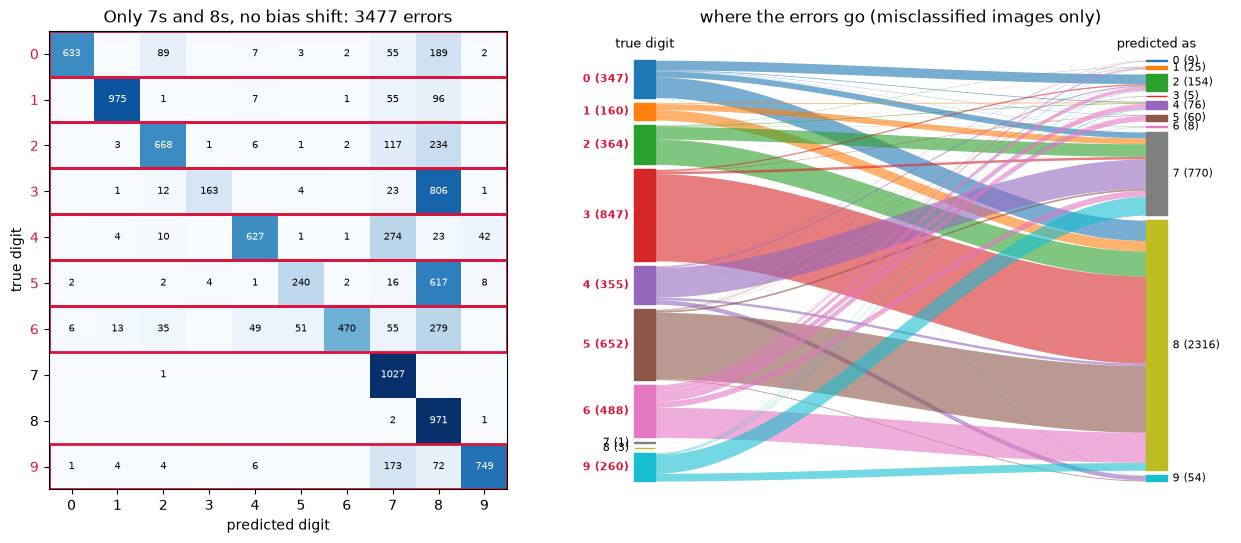

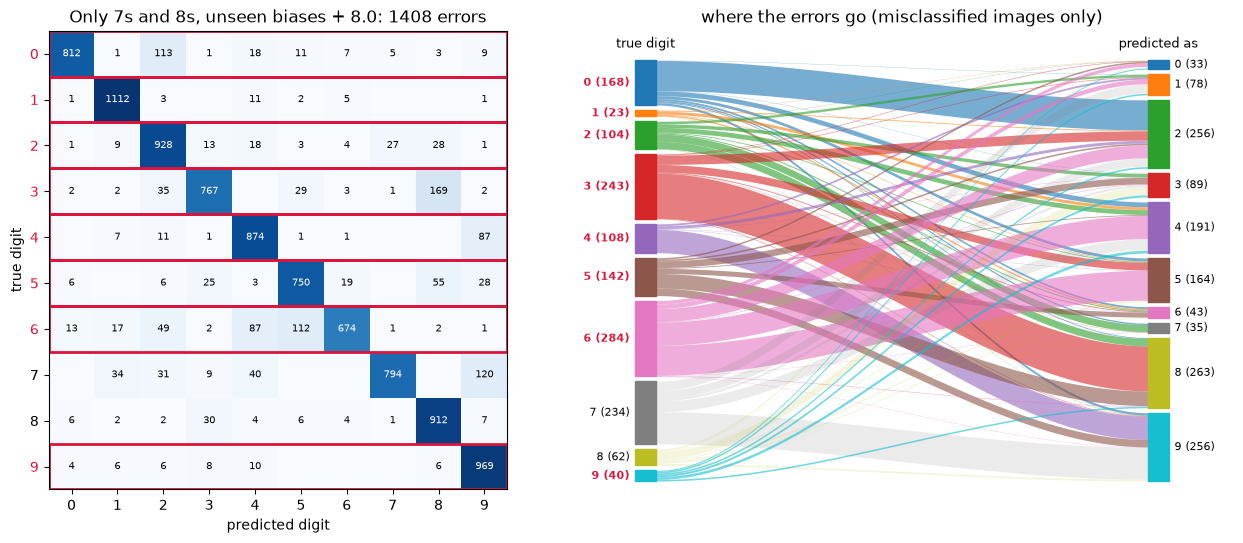

In [24]:
from plots import predictions, show_predictions

unseen = STUDENT_ONLY78["exclude_digits"]
show_predictions(y_test, predictions(only78_model, x_test), highlight=unseen, title="Only 7s and 8s, no bias shift")
show_predictions(y_test, predictions(only78_model, x_test, unseen, best78[0]), highlight=unseen, title=f"Only 7s and 8s, unseen biases + {best78[0]}")